# 1. Introducción



## 1.1 Descripción del dataset
El dataset que elegí para realizar el trabajo contiene un archivo con los resultados de partidos de selecciones masculinas de fútbol, desde 1872 hasta 2026: unos 49.900 partidos, con fecha, selecciones, goles, torneo, ciudad, país y si se jugó en cancha neutral o no.

Además se complementa con otro archivo de goles, con unos 48.000 registros: goleador, minuto, si fue de penal y si fue gol en contra.

## 1.2 Fuente y contexto
La fuente es un repositorio público de GitHub: https://github.com/martj42/international_results

## 1.3 Preguntas guía
1. ¿Cómo le fue a la selección argentina a lo largo de la historia (victorias, empates y derrotas por década)?
2. ¿Quiénes son los máximos goleadores de Argentina según los goles registrados en el dataset?

# 2. Exploración inicial




## 2.1 Carga de los datos
Se importan las librerías y se leen los dos archivos.

 `results` (unos 49.900 partidos, 9 columnas)

  `goleadores` (47.914 goles, 9 columnas)

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

URL_BASE = "https://raw.githubusercontent.com/martj42/international_results/master/"

results = pd.read_csv(URL_BASE + "results.csv")
goleadores = pd.read_csv(URL_BASE + "goalscorers.csv")

print("results:", results.shape)
print("goleadores:", goleadores.shape)
results.head()

results: (49940, 9)
goleadores: (47914, 9)


,date,home_team,away_team,home_score,away_score,tournament,city,country,neutral
0,1872-11-30,Scotland,England,0,0,Friendly,Glasgow,Scotland,False
1,1873-03-08,England,Scotland,4,2,Friendly,London,England,False
2,1874-03-07,Scotland,England,2,1,Friendly,Glasgow,Scotland,False
3,1875-03-06,England,Scotland,2,2,Friendly,London,England,False
4,1876-03-04,Scotland,England,3,0,Friendly,Glasgow,Scotland,False


## 2.2 Estructura y tipos de datos
Con `.info()` veo que `results` no tiene nulos, pero la columna `date` está como texto y no como fecha. Eso lo arreglo en la limpieza.


In [17]:
# Estructura general
results.info()
print("-" * 40)
goleadores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 49940 entries, 0 to 49939
Data columns (total 9 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   date        49940 non-null  object
 1   home_team   49940 non-null  object
 2   away_team   49940 non-null  object
 3   home_score  49940 non-null  int64 
 4   away_score  49940 non-null  int64 
 5   tournament  49940 non-null  object
 6   city        49940 non-null  object
 7   country     49940 non-null  object
 8   neutral     49940 non-null  bool  
dtypes: bool(1), int64(2), object(6)
memory usage: 3.1+ MB
----------------------------------------
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47914 entries, 0 to 47913
Data columns (total 9 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   date       47914 non-null  object 
 1   home_team  47914 non-null  object 
 2   away_team  47914 non-null  object 
 3   team       47914 non-null  object 
 4  

## 2.3 Estadísticas descriptivas
El local mete más goles que el visitante en promedio (1,76 contra 1,18). Hay un partido con 31 goles de un equipo (Australia 31-0 Samoa Americana, 2001): es raro pero real, así que lo dejo.


In [18]:
# Resumen estadistico
print(results.describe())
print("-" * 40)
print(goleadores.describe())

         home_score    away_score
count  49940.000000  49940.000000
mean       1.756187      1.182679
std        1.772111      1.401672
min        0.000000      0.000000
25%        1.000000      0.000000
50%        1.000000      1.000000
75%        2.000000      2.000000
max       31.000000     21.000000
----------------------------------------
             minute
count  47660.000000
mean      50.074360
std       26.377515
min        1.000000
25%       28.000000
50%       51.000000
75%       73.000000
max      122.000000


## 2.4 Diagnóstico de calidad
`results` está limpio. En `goleadores` faltan 44 goleadores, 254 minutos y casi todas las asistencias, y hay 79 filas repetidas. Lo resuelvo en la sección siguiente.


In [19]:
# Primer diagnóstico de calidad: faltantes y duplicados
print("Faltantes en results:", results.isna().sum().sum())
print("Duplicados en results:", results.duplicated().sum())
print("-" * 40)
print("Faltantes en goleadores:")
print(goleadores.isna().sum())
print("Duplicados en goleadores:", goleadores.duplicated().sum())

Faltantes en results: 0
Duplicados en results: 0
----------------------------------------
Faltantes en goleadores:
date             0
home_team        0
away_team        0
team             0
scorer          44
minute         254
own_goal         0
penalty          0
assist       45838
dtype: int64
Duplicados en goleadores: 79


# 3. Limpieza de datos

## 3.1 Corrección de formatos (fechas)
Paso `date` de texto a fecha con `pd.to_datetime`, así después puedo sacar el año y la década.


In [20]:
# Pasamos date de texto a fecha real (datetime)
results["date"] = pd.to_datetime(results["date"])
goleadores["date"] = pd.to_datetime(goleadores["date"])

print(results["date"].dtype)

datetime64[ns]


## 3.2 Filas repetidas
Las 79 filas repetidas parecían duplicados, pero antes de borrar las revisé: en los 35 partidos donde aparecen, la cantidad de goles coincide con el marcador. Son goles reales del mismo jugador (sin minuto cargado), así que no las borro.


In [21]:
# Filas repetidas (todas las columnas iguales)
filas_dup = goleadores[goleadores.duplicated(keep=False)]
print(filas_dup.head(6))
print("Filas repetidas:", goleadores.duplicated().sum())

# Control con un ejemplo: Ghana vs Etiopía, 26/11/1963
print(goleadores[(goleadores["date"] == "1963-11-26") & (goleadores["home_team"] == "Ghana")][["team", "scorer", "minute"]])
print(results[(results["date"] == "1963-11-26") & (results["home_team"] == "Ghana")][["home_team", "away_team", "home_score", "away_score"]])

           date home_team away_team      team            scorer  minute  \
4059 1963-11-26     Ghana  Ethiopia     Ghana     Edward Acquah     NaN   
4060 1963-11-26     Ghana  Ethiopia     Ghana     Edward Acquah     NaN   
4063 1963-11-28  Ethiopia   Tunisia  Ethiopia    Mengistu Worku     NaN   
4064 1963-11-28  Ethiopia   Tunisia  Ethiopia    Mengistu Worku     NaN   
4067 1963-11-28   Nigeria     Sudan     Sudan  Nasr Eddin Abbas     NaN   
4068 1963-11-28   Nigeria     Sudan     Sudan  Nasr Eddin Abbas     NaN   

      own_goal  penalty assist  
4059     False    False    NaN  
4060     False    False    NaN  
4063     False    False    NaN  
4064     False    False    NaN  
4067     False    False    NaN  
4068     False    False    NaN  
Filas repetidas: 79
       team         scorer  minute
4059  Ghana  Edward Acquah     NaN
4060  Ghana  Edward Acquah     NaN
     home_team away_team  home_score  away_score
5977     Ghana  Ethiopia           2           0


In [22]:
# Revisión de todos los partidos con filas repetidas
partidos_dup = goleadores[goleadores.duplicated()][["date", "home_team", "away_team"]].drop_duplicates()
print("Partidos con filas repetidas:", len(partidos_dup))

coinciden = 0
for i in range(len(partidos_dup)):
    p = partidos_dup.iloc[i]
    filas_goles = goleadores[(goleadores["date"] == p["date"]) & (goleadores["home_team"] == p["home_team"]) & (goleadores["away_team"] == p["away_team"])]
    marcador = results[(results["date"] == p["date"]) & (results["home_team"] == p["home_team"]) & (results["away_team"] == p["away_team"])]
    total_marcador = marcador["home_score"].iloc[0] + marcador["away_score"].iloc[0]
    if len(filas_goles) == total_marcador:
        coinciden += 1

print("Partidos donde los goles registrados coinciden con el marcador:", coinciden)

Partidos con filas repetidas: 35
Partidos donde los goles registrados coinciden con el marcador: 35


## 3.3 Valores faltantes
- `scorer`: pongo "Desconocido" para no perder esos 44 goles.
- `assist`: la saco, está vacía casi en su totalidad (96%) y no la necesito.
- `minute`: dejo los 254 faltantes como están. Rellenarlos sería inventar minutos.


In [23]:
# scorer: sin nombre = "Desconocido"
goleadores["scorer"] = goleadores["scorer"].fillna("Desconocido")

# assist: 96% vacía = la sacamos
goleadores = goleadores.drop(columns=["assist"])

# Chequeamos
print(goleadores.isna().sum())
print(goleadores.shape)

date           0
home_team      0
away_team      0
team           0
scorer         0
minute       254
own_goal       0
penalty        0
dtype: int64
(47914, 8)


# 4. Transformaciones

## 4.1 Columnas nuevas
Creo `anio` y `decada` a partir de la fecha, y `resultado_arg` (Victoria, Empate o Derrota) con `np.select`, mirando si Argentina jugó de local o de visitante.


In [24]:
results["anio"] = results["date"].dt.year
results["decada"] = results["anio"] // 10 * 10

local = results["home_team"] == "Argentina"
visitante = results["away_team"] == "Argentina"
gl = results["home_score"]
gv = results["away_score"]

gana   = (local & (gl > gv)) | (visitante & (gv > gl))
empata = (local | visitante) & (gl == gv)
pierde = (local & (gl < gv)) | (visitante & (gv < gl))

results["resultado_arg"] = np.select([gana, empata, pierde], ["Victoria", "Empate", "Derrota"], default="No juega")
print(results["resultado_arg"].value_counts())

resultado_arg
No juega    48861
Victoria      602
Empate        256
Derrota       221
Name: count, dtype: int64


## 4.2 Partidos de Argentina y resultados por década
Me quedo con los 1.079 partidos de Argentina (1902 a 2026) y armo con `pd.crosstab` el porcentaje de victorias, empates y derrotas de cada década. La de 2020 está incompleta.


In [25]:
arg = results[results["resultado_arg"] != "No juega"]
print("Partidos de Argentina:", len(arg))
print("Desde:", arg["date"].min().year, "hasta:", arg["date"].max().year)

tabla_decadas = pd.crosstab(arg["decada"], arg["resultado_arg"], normalize="index") * 100
print(tabla_decadas.round(1))

Partidos de Argentina: 1079
Desde: 1902 hasta: 2026
resultado_arg  Derrota  Empate  Victoria
decada                                  
1900              25.0    25.0      50.0
1910              33.8    15.4      50.8
1920              23.0    25.7      51.4
1930              20.0    15.0      65.0
1940              11.9    15.3      72.9
1950              19.7    18.2      62.1
1960              27.8    26.7      45.6
1970              24.0    26.9      49.0
1980              27.0    36.0      37.1
1990              19.0    30.2      50.8
2000              18.9    22.0      59.1
2010              16.4    24.3      59.3
2020               6.9    14.9      78.2


In [26]:
print("Partidos de Argentina por década:")
print(arg["decada"].value_counts().sort_index())

Partidos de Argentina por década:
decada
1900     12
1910     65
1920     74
1930     40
1940     59
1950     66
1960     90
1970    104
1980     89
1990    126
2000    127
2010    140
2020     87
Name: count, dtype: int64


## 4.3 Goles de Argentina y tramos de minutos
Agrupo los minutos en tramos de 15 con `pd.cut` y filtro los goles de Argentina, sin contar los en contra. Ojo: el archivo registra 984 goles de los 2.058 reales (un 48%), así que el ranking es de goles registrados, no totales.


In [27]:
goleadores["tramo"] = pd.cut(goleadores["minute"], bins=[0, 15, 30, 45, 60, 75, 90, 130],
                             labels=["1-15", "16-30", "31-45", "46-60", "61-75", "76-90", "91+"])

goles_arg = goleadores[(goleadores["team"] == "Argentina") & (goleadores["own_goal"] == False)]
print("Goles de Argentina registrados:", len(goles_arg))

goles_reales = np.select([local, visitante], [gl, gv], default=0).sum()
print("Goles de Argentina según los marcadores:", goles_reales)
print("Cobertura:", round(len(goles_arg) / goles_reales * 100, 1), "%")

top10 = goles_arg["scorer"].value_counts().head(10)
print(top10)

Goles de Argentina registrados: 984
Goles de Argentina según los marcadores: 2058
Cobertura: 47.8 %
scorer
Lionel Messi               71
Gabriel Batistuta          37
Hernán Crespo              26
Lautaro Martínez           25
Gonzalo Higuaín            23
Sergio Agüero              20
Norberto Doroteo Méndez    17
Ángel Di María             17
Diego Maradona             15
Juan Román Riquelme        15
Name: count, dtype: int64


# 5. Visualización

## 5.1 Resultados de Argentina por década
Argentina ganó más de la mitad de sus partidos en la mayoría de las décadas, salvo entre los 60 y los 80. Lo mejor fueron los años 40 (73% de victorias) y lo peor los 80 (37%, con muchos empates). Desde los 90 las victorias suben. Los 2020 dan 78%, pero la década no terminó.


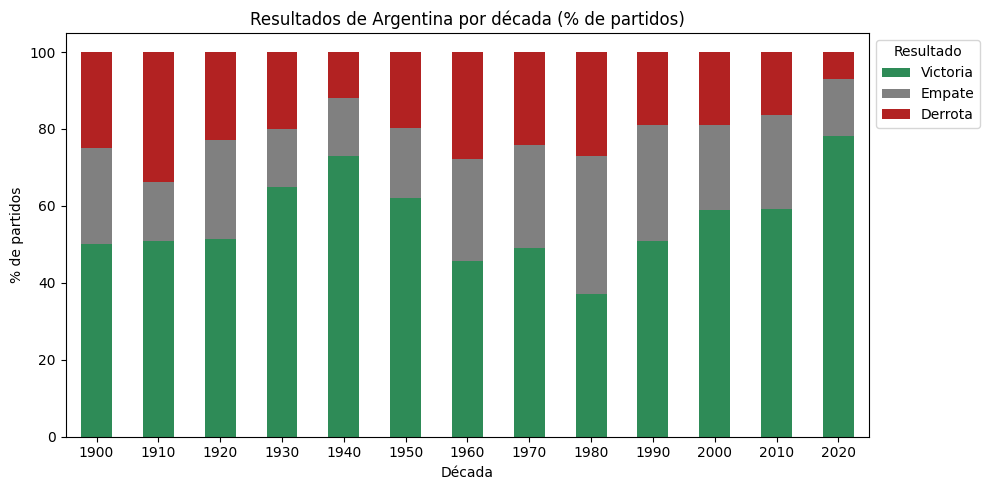

In [28]:
tabla_decadas = tabla_decadas[["Victoria", "Empate", "Derrota"]]
tabla_decadas.plot(kind="bar", stacked=True, figsize=(10, 5), color=["seagreen", "gray", "firebrick"])
plt.title("Resultados de Argentina por década (% de partidos)")
plt.xlabel("Década")
plt.ylabel("% de partidos")
plt.legend(title="Resultado", loc="upper left", bbox_to_anchor=(1, 1))
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

## 5.2 Máximos goleadores
Messi lidera con 71 goles registrados, casi el doble que Batistuta (37). Son números mínimos, porque al dataset le faltan muchos goles.


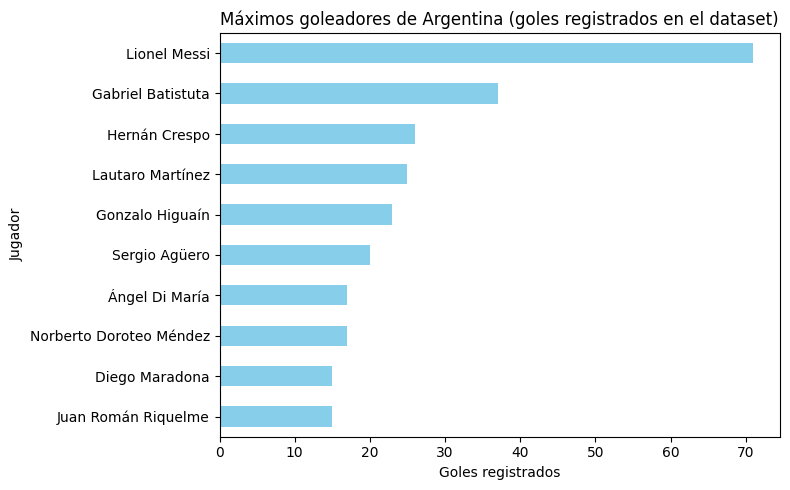

In [29]:
top10.sort_values().plot(kind="barh", figsize=(8, 5), color="skyblue")
plt.title("Máximos goleadores de Argentina (goles registrados en el dataset)")
plt.xlabel("Goles registrados")
plt.ylabel("Jugador")
plt.tight_layout()
plt.show()

## 5.3 Goles por tramo de minutos
Los goles se reparten bastante parejo. El tramo con más es el de 76-90 (184), pero la diferencia con el resto es chica.


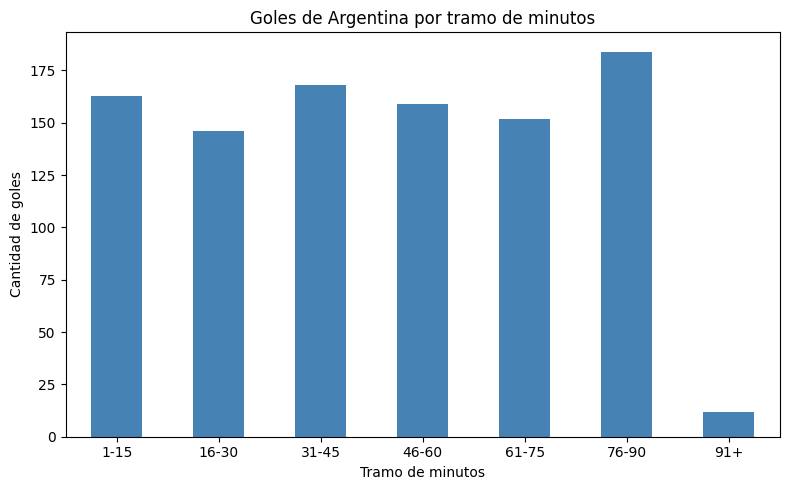

In [30]:
por_tramo = goles_arg["tramo"].value_counts().sort_index()
por_tramo.plot(kind="bar", figsize=(8, 5), color="steelblue")
plt.title("Goles de Argentina por tramo de minutos")
plt.xlabel("Tramo de minutos")
plt.ylabel("Cantidad de goles")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 6. Conclusiones

## 6.1 Pregunta 1: ¿cómo le fue a Argentina a lo largo de la historia?
Argentina jugó 1.079 partidos según los datos del dataset (1902 a 2026): ganó 602 (55,8%), empató 256 (23,7%) y perdió 221 (20,5%). Es decir, ganó más de la mitad de sus partidos.

Por década, el rendimiento no fue parejo:
- El mejor período fue la década de 1940, con 72,9% de victorias, y el peor fue la década de 1980, con 37,1% de victorias.
- Como dato relevante, desde los 90 el porcentaje de victorias sube y se mantiene arriba del 50%.
- La década de 2020 muestra 78,2%, pero todavía está incompleta y no es comparable de forma directa con las anteriores.

Los números son muy positivos, aunque este análisis solo mira a Argentina y no la compara con otras selecciones. Como contexto externo al dataset, esto es coherente con los títulos de la selección: 3 Copas del Mundo y 16 Copas América.

## 6.2 Pregunta 2: ¿quiénes son los máximos goleadores?
Según los goles registrados en el dataset, el máximo goleador de Argentina es Lionel Messi (71), seguido por Gabriel Batistuta (37), Hernán Crespo (26), Lautaro Martínez (25) y Gonzalo Higuaín (23). Messi casi duplica al segundo.

Por tramos de minutos, los goles se reparten de forma bastante pareja. El tramo con más goles es el de 76-90 (184), pero la diferencia con los demás es chica, así que no es una conclusión firme.

Como es de esperar, el máximo goleador es Messi, a quien muchos consideran el mejor jugador de la historia (esto es una opinión mía, no sale de los datos), y eso a pesar de que faltan goles en el dataset. Lo que sí me sorprende es que el tramo con más goles sea el de los minutos 76 a 90. Lo esperaba al revés: en el último tramo del tiempo reglamentario cada vez queda menos tiempo y llegar al gol parece más difícil. Pero también es el momento más agónico del partido, donde un gol puede cambiar la historia. Igual, la diferencia con los otros tramos es chica, así que no lo tomo como una conclusión firme.

## 6.3 Limitaciones y reflexión final
- **Primeras décadas con pocos partidos:** la década de 1900 tiene solo 12 partidos de Argentina (contra 65 o más en las siguientes), así que sus porcentajes son poco confiables.
- **Goles incompletos:** el archivo de goleadores registra 984 goles de Argentina, contra 2.058 según los marcadores (cobertura de ~48%). El ranking de goleadores es un piso y no el total real.
- **Década de 2020 incompleta**, como se aclaró antes.

**Reflexión final:** Haber elegido un tema que me gusta en lo personal hizo que el trabajo fuera más llevadero e interesante. Conocí datos más exactos sobre la selección argentina de fútbol, por más que falten algunos datos relevantes. Hubo cosas que me esperaba, como los goleadores y el porcentaje de victorias en la historia, pero también descubrí datos que no conocía, como la década en la que "peor nos fue" y cuál fue la mejor.
También, si tuviera que agregarle más cosas, compararía a Argentina con otras selecciones, porque con este análisis solo puedo hablar de ella.